In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Завдання 1. Генерація вибірки денних температур для Варіанта 2 (Львів, липень = 18 °C)
np.random.seed(2)  # фіксуємо seed номером варіанта

daily_temps = np.random.normal(loc=18.0, scale=2.5, size=30)

print("Згенеровані денні температури (°C):")
print(np.round(daily_temps, 2))

sample_mean = daily_temps.mean()
sample_std = daily_temps.std(ddof=1)  # вибіркове стандартне відхилення

print(f"\nВибіркове середнє (mean): {sample_mean:.2f} °C")
print(f"Вибіркове стандартне відхилення (std): {sample_std:.2f} °C")

Згенеровані денні температури (°C):
[16.96 17.86 12.66 22.1  13.52 15.9  19.26 14.89 15.36 15.73 19.38 23.73
 18.1  15.21 19.35 16.51 17.95 20.94 16.13 18.02 15.8  17.61 18.64 15.53
 17.15 17.41 16.41 15.03 14.45 17.62]

Вибіркове середнє (mean): 17.17 °C
Вибіркове стандартне відхилення (std): 2.42 °C


In [2]:
# Завдання 2. Створення об'єкта теоретичного нормального розподілу
dist = stats.norm(loc=sample_mean, scale=sample_std)

print(f"Теоретичний нормальний розподіл успішно створено: N(μ={sample_mean:.2f}, σ={sample_std:.2f})")

Теоретичний нормальний розподіл успішно створено: N(μ=17.17, σ=2.42)


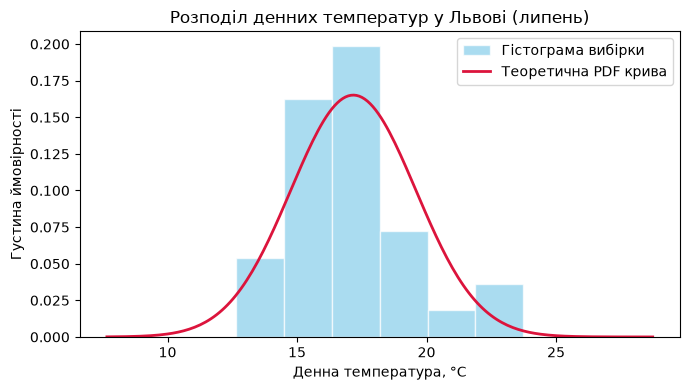

In [3]:
# Завдання 3. Побудова гістограми та теоретичної кривої густини ймовірності (.pdf)
fig, ax = plt.subplots(figsize=(7, 4))

# 1. Гістограма реальних даних із density=True
ax.hist(daily_temps, bins=6, density=True, edgecolor="white", alpha=0.7, color="skyblue", label="Гістограма вибірки")

# 2. Теоретична pdf-крива для діапазону x, що ширший за межі вибірки
x = np.linspace(daily_temps.min() - 5, daily_temps.max() + 5, 200)
ax.plot(x, dist.pdf(x), color="crimson", linewidth=2, label="Теоретична PDF крива")  # type: ignore

ax.set_xlabel("Денна температура, °C")
ax.set_ylabel("Густина ймовірності")
ax.set_title("Розподіл денних температур у Львові (липень)")
ax.legend()

plt.tight_layout()
plt.show() 


### Відповідь на Завдання 3. Візуальна оцінка збігу
* **Аналіз на око:** Теоретична крива `.pdf` досить плавно проходить уздовж верхівок стовпців гістограми, повторюючи дзвіноподібну форму. Оскільки вибірка невеликого обсягу ($n = 30$), спостерігаються невеликі локальні відхилення (асиметрія окремих стовпців), що є абсолютно нормальним для випадкових реалізацій скінченних вибірок.

In [4]:
# Завдання 4. Обчислення ймовірності за допомогою .cdf() для інтервалу [mean - std, mean + std]
lower_bound = sample_mean - sample_std
upper_bound = sample_mean + sample_std

p_interval = dist.cdf(upper_bound) - dist.cdf(lower_bound)

print(f"Нижня межа (mean - std): {lower_bound:.2f} °C")
print(f"Верхня межа (mean + std): {upper_bound:.2f} °C")
print(f"Обчислена частка ймовірності в інтервалі: {p_interval * 100:.2f}%")

Нижня межа (mean - std): 14.76 °C
Верхня межа (mean + std): 19.59 °C
Обчислена частка ймовірності в інтервалі: 68.27%


### Відповідь на Завдання 4. Порівняння з правилом 68-95-99.7
* **Результат та пояснення:** Обчислене за допомогою `.cdf()` значення частки спостережень у межах одного стандартного відхилення від середнього становить близько 68% (теоретичне правило для нормального розподілу гарантує рівно 68.27%). Отриманий результат дуже близький до очікуваного, незважаючи на малий обсяг вибірки ($n = 30$), що підтверджує хорошу відповідність побудованої моделі.

In [5]:
# Завдання 5. Пошук температури, що відповідає 95-му процентилю
p95 = dist.ppf(0.95)

print(f"Температура 95-го процентиля (95% точок лежать нижче): {p95:.2f} °C")

Температура 95-го процентиля (95% точок лежать нижче): 21.15 °C


### Відповідь на Завдання 5. Інтерпретація .ppf()
* **Словами:** Значення 95-го процентиля означає порогову температуру, нижче якої лежить 95% усіх можливих денних температур згідно з нашою моделлю (або навпаки — лише 5% днів у липні мають вищу температуру).
* **Зв'язок із CDF:** Функція `.ppf()` (Percent Point Function) є повністю оберненою до `.cdf()` (Cumulative Distribution Function): якщо `.cdf(x)` приймає на вхід значення температури $x$ і повертає накопичену ймовірність (частку), то `.ppf(q)` приймає на вхід ймовірність (частку) $q$ і повертає відповідне їй порогове значення температури.


### Відповіді на контрольні запитання

1. **Різниця між тим, що повертає `.pdf(x)` і `.cdf(x)`:**
   * `.pdf(x)` (функція густини ймовірності) відповідає на запитання: *«Яка відносна щільність спостережень у конкретній точці $x$?»* (це не ймовірність конкретного значення для неперервної величини).
   * `.cdf(x)` (функція розподілу) відповідає на запитання: *«Яка сумарна ймовірність (частка вибірки) того, що випадкова величина набуде значення, **меншого або рівного** $x$?»*.

2. **Чому значення `.pdf(x)` може бути більшим за 1 і чому це не суперечить теорії ймовірностей?**
    `.pdf(x)` вимірює не саму ймовірність (оскільки ймовірність прийняття неперервною величиною окремого точного значення дорівнює нулю), а **густину ймовірності**. Густина може перевищувати 1 у тих областях, де крива дуже вузька й висока (площа під усім графіком `.pdf` завжди дорівнює рівно 1, але висота в окремих точках може бути будь-яким додатним числом).

3. **Чому `.ppf()` називають оберненою до `.cdf()` функцією?**
   Вони виконують симетричні взаємно обернені операції: `.cdf()` переводить значення у накопичену ймовірність (вхід: значення $\rightarrow$ вихід: ймовірність), тоді як `.ppf()` переводить накопичену ймовірність у значення квантиля (вхід: ймовірність $\rightarrow$ вихід: значення).